# 04 · What else can we see? Insights for each stakeholder

Notebooks 02–03 answer "what are calls about" and "how do people feel". Leaders need something more specific:

| Stakeholder | Question they actually have | Insight below |
|---|---|---|
| **Engineering leadership** | What's going to break next — and did we know? | 1. Early-warning risk radar (implemented + backtested) |
| **Exec / Eng / CS** | How far did the outage really reach, and what did the fix cost us? | 2. Outage blast radius & the second wave (implemented) |
| **CS & Sales leaders** | Which accounts need a call this week, and why? | 3. Account watch list (implemented) |
| **Product & Sales** | What do at-risk customers want, and who are we losing to? | 4. Demand & competitive intelligence (implemented) |
| Various | — | 5. Three ideas written up but not built |

Everything here reuses the layers already built (extraction, topics, sentiment). One extra LLM pass — risk triage on the
30 internal calls — cost **$0.88**. All responses are cached; this notebook runs offline.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore")
from transcript_intel import load_tables, insights, llm
from transcript_intel.preprocess import redact
from transcript_intel.sentiment import period, OUTAGE_START, OUTAGE_END, COMPLY_V2_GA

pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"support": "#d95f02", "external": "#1b9e77", "internal": "#7570b3"}
REPORTS = Path.cwd().parent / "reports"
ASOF = pd.Timestamp("2026-04-29", tz="UTC")      # "today" = day after the last call in the dataset

calls, sentences, _ = load_tables()
red = redact(sentences)
calls_x = pd.read_pickle("../cache/extraction_calls.pkl")        # notebook 02, LLM extraction
issues = pd.read_pickle("../cache/extraction_issues.pkl")
ct = pd.read_pickle("../cache/call_type_check.pkl")[["meeting_id", "llm_incident"]]
labels = pd.read_csv(REPORTS / "call_theme_labels.csv")
themes = labels[(labels.confidence >= 0.6) | labels.is_primary]
call_sent = pd.read_csv(REPORTS / "call_sentiment.csv", parse_dates=["start"])   # notebook 03

## 1. Early-warning risk radar — *for engineering leadership*

**The question:** the March outage cost us the quarter's sentiment and a string of renewals. Was it visible beforehand?

### 1a. Tracing the outage back
Take the root cause as stated in the post-incident RCA call, and search every issue extracted *before* 10 March for the
most similar statements (sentence embeddings, cosine similarity). No hindsight-written query — the seed is the RCA's own words.

In [2]:
seed = issues[issues.title.str.contains("Root Cause Analysis") & (issues["rank"] == 0)].statement.tolist()
print("Seed (RCA root cause):", seed[0])
top, sims = insights.precursors(issues, seed, before=OUTAGE_START)
print(f"Similarity of all {len(sims)} pre-outage issues: median {sims.median():.2f}, 98th pct {sims.quantile(.98):.2f}")
top[["start", "title", "call_type", "similarity", "statement"]].assign(start=lambda d: d.start.dt.date).round(2)

Seed (RCA root cause): Event ingestion pipeline has a single point of failure that was known but deprioritized in favor of feature work.
Similarity of all 180 pre-outage issues: median 0.27, 98th pct 0.60


,start,title,call_type,similarity,statement
197,2026-02-05,Detect Team - Sprint Planning,internal,0.75,"Event ingestion pipeline runs on a single processing node with no redundancy or circuit breaker, risking t..."
246,2026-03-02,Detect Team - Sprint Planning,internal,0.75,Single ingestion node is a single point of failure that could create blind spots in event processing under...
523,2026-02-07,Aegis / Blackridge Investments - Renewal Discussion,external,0.67,"Threat detection event ingestion pipeline suffered a cascading failure from a single point of failure, cau..."
12,2026-02-16,Weekly Engineering Standup,internal,0.62,Event ingestion refactor still needs dead letter queue handling and retry logic completion before integrat...
488,2026-03-09,Aegis / Keystone Health - Renewal Planning,external,0.58,Threat detection event ingestion pipeline failure reduced monitoring visibility for some customers
412,2026-02-28,All Hands - February Wrap,internal,0.50,Intermittent event processing test failures that pass on rerun and are hard to diagnose
26,2026-02-26,SOC 2 Audit Preparation - Internal,internal,0.49,"Integration between the customer ticketing system and the incident alerting system fails intermittently, p..."
299,2026-02-11,Aegis / Brightpath Commerce - Detect Module Deployment,external,0.48,Customer is concerned about the reliability of threat detection after a past event ingestion pipeline outa...


In [3]:
# What was actually said, in the source transcripts
def said(title, date, pattern):
    mid = calls[(calls.title == title) & (calls.start.dt.strftime("%Y-%m-%d") == date)].meeting_id.iloc[0]
    g = sentences[(sentences.meeting_id == mid) & sentences.text.str.contains(pattern, case=False)]
    return [f"{date} · {title} · {r.speaker}: “{r.text[:220]}…”" for r in g.head(1).itertuples()]

for line in (said("Detect Team - Sprint Planning", "2026-02-05", "single processing node")
           + said("Aegis / Blackridge Investments - Renewal Discussion", "2026-02-07", "cascading failure")
           + said("Weekly Engineering Standup", "2026-02-16", "redundant node setup")
           + said("Detect Team - Sprint Planning", "2026-03-02", "design spike")
           + said("INCIDENT: Detect Pipeline Failure - War Room", "2026-03-10", "single primary node")):
    print("•", line, "\n")

• 2026-02-05 · Detect Team - Sprint Planning · Ananya Sharma: “Yeah, so basically the event ingestion pipeline right now has... it's all running through a single processing node with no fallback. If that node goes down or gets overwhelmed, we lose event visibility entirely. There's …” 

• 2026-02-07 · Aegis / Blackridge Investments - Renewal Discussion · Ananya Sharma: “Yeah, so I want to be completely transparent with you about that. We did have an incident with the event processing pipeline on the Detect side — this was back in January. There was a cascading failure in the ingestion l…” 

• 2026-02-16 · Weekly Engineering Standup · Mike Romano: “Bit of both, honestly. The dead letter queue piece and the circuit breaker pattern — those are well-understood, I'm not worried about them. The part I'm less sure about is how the redundant node setup interacts with our …” 

• 2026-03-02 · Detect Team - Sprint Planning · Ananya Sharma: “Probably not a full implementation, no. But maybe we sco

> **Finding:** the root cause was discussed in **at least five calls over five weeks** before the outage:
> - **Jan** — a cascading ingestion failure with the *same* root cause already happened (disclosed to Blackridge on 7 Feb).
> - **5 Feb** — an engineer flags "a single processing node with no fallback… no circuit breaker, no redundancy"; a fix is committed.
> - **16 Feb** — the refactor is 60% done, end-of-March deadline at "60/40 odds".
> - **2 Mar** — scope is cut back to a "design spike"; the sprint keeps "comfortable buffer".
> - **10 Mar** — outage. The war-room summary: *"a known tech debt issue that had been flagged but not prioritized."*
>
> Customers saw it too: Brightpath (11 Feb) and Keystone (9 Mar) raised the earlier pipeline failure on their calls.

### 1b. Could a tool have flagged it in advance? A backtest

**Attempt 1 — count mentions.** Score each issue cluster from notebook 02 by internal mentions × (1 + customer mentions)
× severity × recency, using only issues before 10 March:

In [4]:
iss_cl = pd.read_pickle("../cache/issues_clustered.pkl")
cl_names = pd.read_pickle("../cache/clusters_named.pkl").set_index("cluster").name
d = iss_cl[(iss_cl.start < OUTAGE_START) & (iss_cl.cluster >= 0)]
g = d.groupby("cluster")
vol = pd.DataFrame({
    "internal_calls": g.apply(lambda x: x[x.call_type == "internal"].meeting_id.nunique()),
    "customer_calls": g.apply(lambda x: x[x.call_type != "internal"].meeting_id.nunique()),
    "high_sev_share": g.severity.apply(lambda s: (s == "high").mean()),
    "days_since": g.start.apply(lambda s: (OUTAGE_START - s.max()).days)})
vol["score"] = vol.internal_calls * (1 + vol.customer_calls) * (0.5 + vol.high_sev_share) * np.where(vol.days_since <= 21, 1, 0.5)
vol["name"] = cl_names.reindex(vol.index)
vol = vol[vol.internal_calls >= 1].sort_values("score", ascending=False).reset_index(drop=True)
vol.index += 1
vol.head(7).round(2)

,internal_calls,customer_calls,high_sev_share,days_since,score,name
1,3,9,0.16,2,19.80,Identity SSO and QA Testing Gaps
2,3,6,0.09,2,12.41,Onboarding and integration setup effort
3,2,8,0.17,0,12.00,Manual Compliance Audit Preparation
4,1,9,0.38,5,8.81,Backup Job Performance and Restore Gaps
5,2,7,0.00,2,8.00,Comply module adoption and framework needs
6,2,3,0.20,0,5.60,Detect Ingestion Pipeline Outage
7,1,6,0.27,0,5.41,MFA and Access Management Gaps


> **Attempt 1 failed:** the pipeline cluster ranks only **6th**, behind chattier topics like Identity SSO and onboarding.
> The warning wasn't loud — it was *specific*. Counting can't see "single point of failure, fix keeps slipping".

**Attempt 2 — read the content.** An LLM pass over each internal call extracts unresolved operational risks with
*customer impact if realised* and *mitigation status* (`schemas.RiskTriage`). The radar then scores each risk:

`impact (1–4) × open-ness (1.0 if not yet being built, else 0.3) × internal calls raising it × (1 + customer calls echoing it) × recency`

Recurrence and customer echoes are matched by embedding similarity (> 0.6). Run it using **only calls before 10 March**:

In [5]:
risks = insights.triage_risks(calls, red)
print(f"{len(risks)} risks from {risks.meeting_id.nunique()} internal calls · evidence quotes grounded {risks.grounded.mean():.0%}")
cols = ["first_raised", "risk", "product", "customer_impact_if_realised", "mitigation_status", "internal_calls", "customer_echoes", "score"]
backtest = insights.risk_radar(risks, issues, asof=OUTAGE_START)
backtest[cols].head(6).round(1)

76 risks from 28 internal calls · evidence quotes grounded 100%


,first_raised,risk,product,customer_impact_if_realised,mitigation_status,internal_calls,customer_echoes,score
10,2026-02-05,Detect event ingestion pipeline runs through a single processing node with no redundancy or circuit breake...,Detect,critical,scheduled,4,2,48.0
5,2026-02-26,"Detection alert tuning is out of date, producing many low-signal alerts that staff ignore, so genuine secu...",Detect,high,scheduled,1,1,6.0
20,2026-02-16,"Comply v2 test coverage is behind plan ahead of the April GA, and recovery depends on borrowed QA staff ar...",Comply,medium,scheduled,2,0,4.0
16,2026-02-23,More frequent file index updates needed for the new restore search could contend with backup jobs in the p...,Protect,medium,discussed_only,1,1,4.0
11,2026-02-05,"No CI gate enforces the full test suite before merging config changes, so regressions such as the alert se...",Detect,high,scheduled,1,0,3.0
7,2026-02-09,"No dedicated staging tenant for Identity testing has been provisioned, so new SSO connectors may be releas...",Identity,medium,scheduled,1,0,2.0


> **Finding:** with nothing after 9 March, the radar ranks the Detect ingestion single point of failure **#1 by a factor of 8**
> (score 48 vs 6): critical impact, raised in 4 internal calls, already echoed in 2 customer calls (Blackridge and Keystone,
> both describing the January pipeline failure — checked by hand), and still only "scheduled". **Caveat:** one incident is one backtest — this shows the method *can* work, not that it's reliable.
> Next step: backtest on the incident history from the ticketing system.
>
> **Why it matters:** the signal that predicted the quarter's worst event was in the transcripts, but spread across
> sprint planning, a standup and a renewal call — no single person was in all of them. That's exactly what a cross-call tool is for.

### 1c. The radar today (as of 29 April)

In [6]:
now = insights.risk_radar(risks, issues, asof=ASOF)
now[cols].head(8).round(1)

,first_raised,risk,product,customer_impact_if_realised,mitigation_status,internal_calls,customer_echoes,score
74,2026-02-05,"Detect event ingestion pipeline lacks health monitoring and alerting between inputs and outputs, so failur...",Detect,high,scheduled,9,24,675.0
36,2026-03-11,"Support escalation and incident response processes were too slow during a major outage, and no improvement...",Detect,high,none,5,13,210.0
35,2026-03-11,"Incident runbook is missing sections on the detection pipeline, which could slow response to a future outage.",Detect,medium,scheduled,3,13,84.0
54,2026-03-02,Redundant ingestion nodes and circuit breaker added after the outage have only been validated by a tableto...,Detect,critical,scheduled,7,1,56.0
13,2026-02-12,"On-demand report generation API rate limits are not finalized, and high per-customer limits across many en...",Comply,medium,discussed_only,2,2,12.0
66,2026-04-15,"Protect backup job scheduler cannot handle concurrent dispatch at higher scale, causing backup queue times...",Protect,critical,scheduled,1,2,12.0
75,2026-03-11,Protect architecture may contain single points of failure similar to those that caused the Detect outage.,Protect,high,discussed_only,3,0,9.0
32,2026-04-17,"On-demand compliance report generation times out for tenants with large audit log datasets, affecting mid-...",Comply,high,in_progress,1,8,8.1


> **Finding — Protect today looks like Detect in February:**
> - *"Protect backup job scheduler cannot handle concurrent dispatch… queue times balloon to 47+ minutes"* — **critical**,
>   raised 15 Apr, and customers are already feeling it: Silverline's backup jobs now overrun into business hours.
> - *"Protect architecture may contain single points of failure similar to those that caused the Detect outage"* — raised in
>   3 internal calls, **discussed only, nothing scheduled**.
> - The new Detect failover has only been validated by a **tabletop simulation**, not a live node-failure test — critical.
> - Comply on-demand reports time out for large tenants (in progress) — worth watching as Comply v2 adoption grows.
>
> **Caveat on "customer echoes":** matching at similarity > 0.6 links statements on the same *topic*, not necessarily the
> same failure — e.g. the Comply timeout risk is "echoed" by customers complaining about manual evidence gathering. Echo
> counts are a pointer for a human to check, not evidence on their own; the Detect backtest echoes above were checked.
>
> **Recommendation:** before the next sprint, (1) run a live failover test on Detect, (2) commission the same
> single-point-of-failure review for Protect that Detect got *after* its outage, and (3) give the radar a weekly slot in
> engineering leadership review — a risk that stays "scheduled" across three calls is a slipping commitment.

## 2. Outage blast radius & the second wave — *for exec, engineering and CS*

**The question:** the incident channel says the outage lasted ~6 hours on 10 March. How long did it last in our *conversations*?

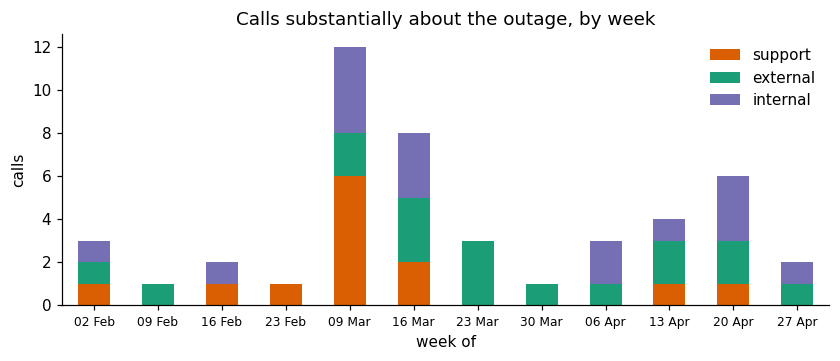

Calls about the outage: 46 ({'external': 17, 'internal': 16, 'support': 13})
Customer accounts in those calls: 21 of 32
Last outage-related call: 2026-04-28 — 49 days after the outage
Title keyword rule finds 15 incident calls; content (LLM) finds 37


In [7]:
c = calls.merge(ct)
c["outage_topic"] = c.meeting_id.isin(themes[themes.theme.str.startswith("Outage")].meeting_id)
c["week"] = c.start.dt.tz_localize(None).dt.to_period("W").dt.start_time
wk = c[c.outage_topic].pivot_table(index="week", columns="call_type", values="meeting_id", aggfunc="count").fillna(0)
ax = wk[["support", "external", "internal"]].plot.bar(stacked=True, figsize=(9, 3.2), color=[COLORS[t] for t in ["support", "external", "internal"]], rot=0)
ax.set_xticklabels([d.strftime("%d %b") for d in wk.index], fontsize=8); ax.set(xlabel="week of", ylabel="calls",
       title="Calls substantially about the outage, by week"); ax.legend(frameon=False); plt.show()

oc = c[c.outage_topic]
print(f"Calls about the outage: {len(oc)} ({oc.call_type.value_counts().to_dict()})")
print(f"Customer accounts in those calls: {oc.account.nunique()} of {calls.account.nunique()}")
print(f"Last outage-related call: {oc.start.max().date()} — {(oc.start.max() - OUTAGE_START).days} days after the outage")
print(f"Title keyword rule finds {calls.incident_flag.sum()} incident calls; content (LLM) finds {c.llm_incident.sum()}")

### The second wave: tickets caused by the fix
April support cases whose root cause, as diagnosed on the call, is the outage *remediation*:

In [8]:
rx = r"(?i)remediation|circuit breaker|rebalanc|prior incident|previous incident"
second = issues[(issues.call_type == "support") & (issues.start >= OUTAGE_END)
                & (issues.statement.str.contains(rx) | issues.evidence_quote.str.contains(rx))]
health = insights.account_health(call_sent, calls_x, insights.competitor_mentions(calls_x), ASOF)
second = second.merge(health[["account", "first_score", "last_score", "watch_score"]], on="account")
second[["start", "title", "statement", "first_score", "last_score", "watch_score"]].assign(start=lambda d: d.start.dt.date)

,start,title,statement,first_score,last_score,watch_score
0,2026-04-22,Support Case #3536 - Stratos Cloud LogVault Integration Timeout,"Circuit breaker payload threshold introduced in a remediation build trips on large batched pushes, blockin...",4.7,2.4,6
1,2026-04-12,Support Case #9856 - Silverline Brands Backup Window Exceeded,Backend infrastructure changes made during remediation of an incident in another product may have affected...,2.4,3.9,2
2,2026-04-15,Support Case #6147 - Summit Trust Detect Alert Delays,Threat detection alerts are consistently delayed by 20-45 minutes due to overloaded processing node cluste...,3.8,2.4,6
3,2026-04-27,Support Case #7615 - Crestline Wealth Group Policy Sync Delay,Remediation changes from a prior incident may have degraded shared cluster resource allocation for other s...,3.8,2.4,5


> **Findings:**
> - The outage stayed in conversation for **49 days**, not 6 hours: **46 calls** discuss it (17 external, 16 internal,
>   13 support), touching **21 of 32 customer accounts**. Call titles flag only 15 calls as incident-related.
> - **The fix generated its own incidents:** four April support cases trace back to remediation changes — a circuit-breaker
>   threshold blocking SIEM forwarding (Stratos), tenant rebalancing delaying alerts (Summit Trust), shared-cluster
>   changes slowing backups and policy sync (Silverline, Crestline). Customers weren't told about the changes.
> - **Three of those four accounts are now on the watch list** (§3). Stratos went from 4.7 to 2.4 — a healthy account
>   made at-risk by the remediation, not by the outage itself.
>
> **Recommendation:** treat remediation as a release, not a hotfix — regression-test it against other products' workloads,
> and tell customers what changed. Measure an incident's cost by the weeks it stays in conversations, not its downtime.

## 3. Account watch list — *for CS and Sales leaders*

**The question:** which accounts need a call this week, and what should the person calling know?

The score is deliberately simple and additive so every point is a reason a CSM can read off the row:
churn risk on the last call (0–3) + customer net-negative on the last call + sentiment fell ≥ 1 point + competitor mentioned
+ **open loop** (latest negative support call with no account-manager call since) + an unresolved support case.

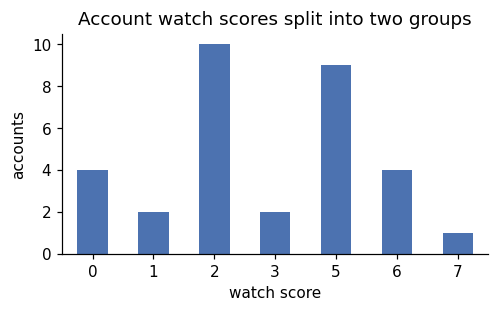

Watch list: 14 of 32 accounts · open loops: 6 · with a competitor named: 10


,account,calls,last_call,last_type,days_since_last,last_score,trend,last_customer_net,churn_risk,competitors,unresolved_support,open_loop,watch_score
19,northstarpharma.com,2,2026-03-15,support,44,2.1,0.0,-0.87,high,"CyberNova, SentinelShield",1,True,7
25,ridgelinelogistics.com,3,2026-03-14,support,45,2.4,-1.0,-0.56,medium,,1,True,6
28,stratoscloud.io,2,2026-04-22,support,6,2.4,-2.3,-0.56,high,,0,True,6
29,summittrust.com,3,2026-04-15,support,13,2.4,-1.4,-0.45,medium,VaultEdge,0,True,6
4,brightpathcommerce.com,4,2026-04-22,external,6,2.6,-1.3,-0.28,high,SentinelShield,0,False,6
12,helixdata.io,1,2026-03-17,external,42,2.3,0.0,-0.73,high,VaultEdge,0,False,5
5,clearwatermed.com,2,2026-04-10,support,18,2.4,-2.4,-0.82,medium,,0,True,5
8,crestlinewealth.com,3,2026-04-27,support,1,2.4,-1.4,-0.58,medium,,0,True,5
23,quantumedge.com,1,2026-03-19,external,40,2.4,0.0,-0.56,high,SentinelShield,0,False,5
14,ironworkscorp.com,1,2026-04-14,external,14,2.6,0.0,-0.48,high,Fortiguard Pro,0,False,5


In [9]:
fig, ax = plt.subplots(figsize=(5, 2.6))
health.watch_score.value_counts().sort_index().plot.bar(ax=ax, rot=0, color="#4c72b0")
ax.set(xlabel="watch score", ylabel="accounts", title="Account watch scores split into two groups"); plt.show()
watch = health[health.watch_score >= 5]
print(f"Watch list: {len(watch)} of {len(health)} accounts · open loops: {watch.open_loop.sum()} · "
      f"with a competitor named: {(watch.competitors != '').sum()}")
watch.drop(columns=["first_score"]).round(2)

In [10]:
# Context for the person picking up the phone: the customer's own words on their latest call
latest = (calls_x.dropna(subset=["account"]).sort_values("start").groupby("account").tail(1)
          .set_index("account")[["start", "title", "one_line_summary", "churn_evidence"]])
latest.loc[watch.account.head(5)].assign(start=lambda d: d.start.dt.date)

,start,title,one_line_summary,churn_evidence
account,,,,
northstarpharma.com,2026-03-15,ESCALATION: Northstar Pharma - Detect Outage Impact on Compliance,Customer escalated a platform-wide Detect event-pipeline outage causing ~9-10 hours of no threat visibilit...,"And I am sitting here right now looking at alternatives. SentinelShield, CyberNova — I've had calls with b..."
ridgelinelogistics.com,2026-03-14,Support Case #5889 - Ridgeline Logistics Detect Latency Issues,Support lead confirms an Aegis-side Detect event ingestion failure caused 45-60 minute alert latency for d...,"I'm not trying to be difficult, I actually like the Detect product when it works. But this is a significan..."
stratoscloud.io,2026-04-22,Support Case #3536 - Stratos Cloud LogVault Integration Timeout,Support diagnosed LogVault HEC timeouts as a circuit breaker payload threshold in the post-incident Detect...,my team has been asking questions about whether Aegis Detect is the right platform for us. We're a fast-gr...
summittrust.com,2026-04-15,Support Case #6147 - Summit Trust Detect Alert Delays,Financial services customer reports 20-45 minute Detect alert delays traced to tenant node imbalance from ...,"When it's not working right and we don't even know it's not working right, that's when it becomes a real p..."
brightpathcommerce.com,2026-04-22,Aegis / Brightpath Commerce - Competitive Evaluation,Account manager addresses a customer's low confidence in Detect after a six-hour March outage and alert fa...,SentinelShield is probably going to come back to us with a pricing proposal in the next week or two. So we...


> **Findings:**
> - Scores split cleanly: **14 of 32 accounts score ≥ 5**, the rest ≤ 3 — no judgment call on the threshold.
> - The watch list is dominated by the outage and its second wave; 10 of 14 named a competitor, most often SentinelShield.
> - **Open loops** — Northstar and Ridgeline have had no contact for ~6 weeks since a negative support call; Stratos,
>   Summit Trust, Clearwater and Crestline are open loops from April.
>
> **Caveats:** there are no renewal outcomes in the data, so this ranks *risk signals*, not predicted churn. An earlier check
> (accounts with an AM follow-up recovered better) is **confounded** — four of the six accounts without follow-up simply had
> their bad call in the last three weeks of the data — so I don't claim follow-ups cause recovery.
>
> **Recommendation:** close the six open loops this week (AM call, not a ticket update); validate the score against
> renewal outcomes from the CRM before trusting its weights.

## 4. Demand & competitive intelligence — *for product and sales*

### 4a. What do customers ask for — weighted by who's at risk?
197 feature requests from extraction, clustered (embeddings + HDBSCAN) and named by the LLM, then sized by how many
**distinct accounts** ask and how many of those are **at risk** (medium/high churn on that call).

197 requests · 31 accounts · 13 clusters · noise 5%


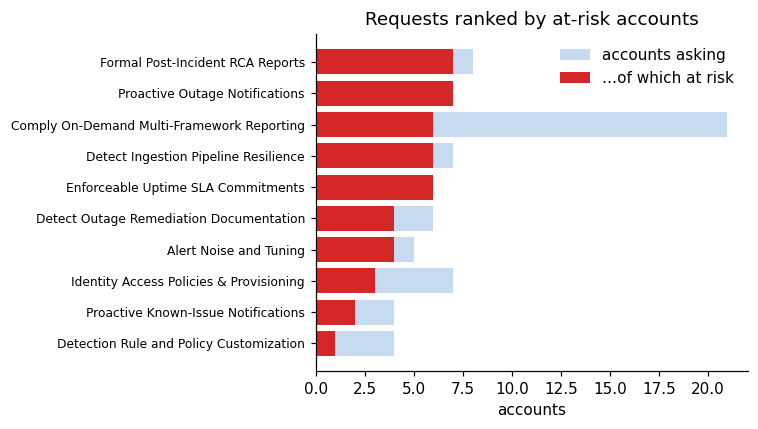

,requests,accounts,at_risk_accounts,internal_mentions,example
name,,,,,
Formal Post-Incident RCA Reports,11,8,7,2,Customer-shareable technical summary of the incident and remediation
Proactive Outage Notifications,11,7,7,2,Proactive outage notifications to affected customers
Comply On-Demand Multi-Framework Reporting,57,21,6,11,"Multi-framework compliance reporting covering ISO 27001, HIPAA, SOC 2 and PCI DSS (previously requested, n..."
Detect Ingestion Pipeline Resilience,15,7,6,6,Redundant processing nodes and circuit breaker for the event ingestion pipeline
Enforceable Uptime SLA Commitments,8,6,6,2,Stronger SLA commitment for at-risk deals
Detect Outage Remediation Documentation,8,6,4,2,Technical remediation documentation for the outage and an engineering call to review architecture changes
Alert Noise and Tuning,9,5,4,3,Behavioral baselining that learns normal activity for the specific environment to reduce false positives
Identity Access Policies & Provisioning,28,7,3,9,Native SSO within Comply (deferred to v2.1)
Proactive Known-Issue Notifications,5,4,2,1,Proactive notifications to customers running agent versions affected by known issues


In [11]:
fr, demand = insights.feature_demand(calls_x)
print(f"{len(fr)} requests · {fr.account.nunique()} accounts · {demand.shape[0]} clusters · noise {(fr.cluster == -1).mean():.0%}")
d = demand.head(10)
fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(d))[::-1]
ax.barh(y, d.accounts, color="#c6dbef", label="accounts asking")
ax.barh(y, d.at_risk_accounts, color="#d62728", label="…of which at risk")
ax.set_yticks(y, d.index, fontsize=8); ax.set_xlabel("accounts"); ax.legend(frameon=False)
ax.set_title("Requests ranked by at-risk accounts"); plt.tight_layout(); plt.show()
demand

> **Findings:**
> - **What at-risk customers ask for is mostly not product engineering.** The top asks by at-risk accounts are
>   *post-incident RCA reports*, *proactive outage notifications*, *enforceable uptime SLAs* and *remediation
>   documentation* — process and communication, deliverable in weeks.
> - **The biggest raw demand — Comply multi-framework reporting (21 accounts) — already shipped in v2**, which explains the
>   launch's sentiment lift (notebook 03) and validates that roadmap bet.
> - Detect pipeline resilience is requested by 6 at-risk accounts — customers want to *see* the architecture fix, not just hear it.
>
> **Recommendation for product:** publish a customer-facing RCA and architecture note, and ship proactive incident
> notifications before the next feature — the cheapest retention lever in the data.

### 4b. Who are we losing to — and when?

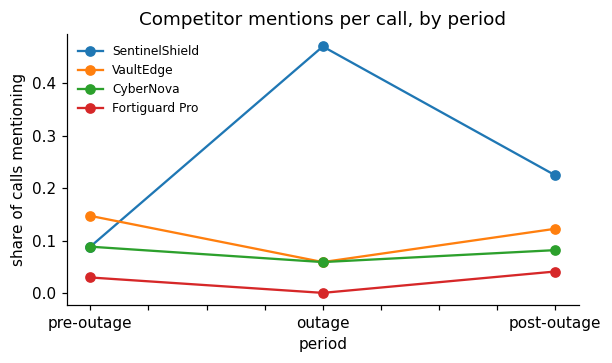

Calls in each period: {'outage': 17, 'post-outage': 49, 'pre-outage': 34}


,mentions,accounts,by_type
competitor,,,
SentinelShield,22,12,"{'external': 10, 'internal': 8, 'support': 4}"
VaultEdge,12,6,"{'internal': 6, 'external': 6}"
CyberNova,8,3,"{'internal': 5, 'external': 2, 'support': 1}"
Fortiguard Pro,3,1,"{'internal': 2, 'external': 1}"
Okta,1,1,{'external': 1}


In [12]:
comp = insights.competitor_mentions(calls_x)
comp["period"] = pd.Categorical(comp.start.map(period), ["pre-outage", "outage", "post-outage"], ordered=True)
n_calls = calls.assign(period=calls.start.map(period)).groupby("period").size()
rate = (comp.groupby(["competitor", "period"], observed=False).meeting_id.nunique().unstack()
            .div(n_calls[["pre-outage", "outage", "post-outage"]], axis=1))
rate = rate.loc[comp.competitor.value_counts().index[:4]]
ax = rate.T.plot(marker="o", figsize=(6, 3.2), title="Competitor mentions per call, by period")
ax.set_ylabel("share of calls mentioning"); ax.legend(frameon=False, fontsize=8); plt.show()
print("Calls in each period:", n_calls.to_dict())
comp.groupby("competitor").agg(mentions=("meeting_id", "size"), accounts=("account", "nunique"),
                                by_type=("call_type", lambda s: dict(s.value_counts()))).sort_values("mentions", ascending=False)

In [13]:
for name in ["SentinelShield", "VaultEdge", "CyberNova"]:
    print(f"— {name}")
    for t in comp[comp.competitor == name].context.head(3):
        print("   •", t)

— SentinelShield
   • Customer's procurement requires a competitive quote for the renewal and SentinelShield is the likely alternative.
   • Customer is evaluating them as a cheaper alternative offering a 99.9% detection uptime SLA.
   • Customer's CISO ordered a formal vendor review and the customer is proceeding with a SentinelShield demo after the outage.
— VaultEdge
   • Appearing mainly in backup and recovery conversations rather than Detect.
   • Reached out to the customer this quarter pitching its compliance module.
   • Wins Protect-led deals by undercutting on backup pricing and claiming sub-15-minute RTO.
— CyberNova
   • Proactively approached a mid-market prospect with a competitive displacement offer after the outage.
   • Named in four of the Q1 closed-lost deals.
   • Customer has held exploratory conversations with CyberNova prompted by the outage and Comply gaps.


> **Findings:**
> - **SentinelShield rides the outage:** mentioned in ~9% of calls before it, ~47% during, ~22% after. Its pitch is aimed
>   squarely at our weak spots — native SIEM integrations (our LogVault connector needs a six-page guide) and a 99.9%
>   detection uptime SLA.
> - **VaultEdge** attacks Protect (backup pricing, sub-15-minute RTO claims) and is moving into compliance;
>   **CyberNova** undercuts Identity on price and was named in four Q1 closed-lost deals.
>
> **Recommendation for sales:** a battlecard pairing the architecture fix with an SLA offer for SentinelShield deals;
> for product: the LogVault connector setup gap was flagged internally in February and deprioritised for bandwidth —
> it is now a competitive liability.

## 5. Ideas written up, not built

**a. Commitment tracker — *for CS and account managers.*** Every call ends with promises: "RCA document by Friday",
"I'll loop in engineering". The provided summaries already list 397 action items. Extract them with owner and due date,
then check later calls with the same account for follow-through ("we never got the RCA"). *Why:* broken promises after an
incident compound the incident; the Northstar, Cobalt and Ironworks calls all ask for documents promised earlier.
*How:* LLM extraction of commitments → match to later calls by account + embedding similarity → open/kept/broken status.

**b. De-escalation playbook — *for support leaders.*** External calls end +0.36 better than they start, support calls
improve far less (notebook 03). Mine the turning points — the lines after which customer sentiment flips — and classify
what the Aegis speaker did (named an owner, gave a date, offered a workaround, apologised). *Why:* a coaching guide grounded
in our own best calls rather than generic training. *How:* change-point detection on customer sentiment within each call →
LLM labels the preceding Aegis turn → compare tactic frequency in calls that recover vs those that don't.
*Care needed:* use it for coaching patterns, not individual performance scoring.

**c. Emerging-theme alarm — *for product ops.*** The fixed taxonomy is only as good as its last curation. Each week,
re-cluster new issue statements and alarm when (i) the share of low-confidence or noise issues rises, or (ii) a new
dense cluster appears that no theme covers. *Why:* the outage would have appeared as a new cluster within days; so would the
remediation side-effects. *How:* the notebook 02 pipeline on a weekly window, plus a drift metric.

## Summary — insights, owners and decisions

| Insight | Finding | Owner | Recommended decision |
|---|---|---|---|
| Early-warning risk radar | Outage root cause raised in 5+ calls over 5 weeks; mention counts rank it 6th, content-based radar ranks it #1 (8× next) | Eng leadership | Weekly radar review; live failover test; Protect SPOF review now |
| Protect is next | Critical scheduler scaling risk (Silverline already affected) + "SPOFs like Detect" discussed only | Eng leadership | Fund the Protect review before it becomes the next outage |
| Blast radius | Outage stayed in conversations 49 days: 46 calls, 21 of 32 accounts (titles flag 15) | Exec | Measure incidents by conversational tail, not downtime |
| Second wave | 4 April tickets caused by remediation; 3 of 4 accounts now on the watch list | Eng | Treat remediation as a release: regression tests + customer change notes |
| Account watch list | 14/32 accounts score ≥ 5; 6 open loops; 10 name a competitor | CS / Sales | Close open loops this week; validate score on CRM renewals |
| Demand by at-risk accounts | Top asks are RCA reports, outage notifications, SLAs — not features | Product | Ship comms + RCA before next feature |
| Competition | SentinelShield mentions ~5× during the outage; pitch targets SIEM setup + uptime SLA | Sales / Product | Battlecard + LogVault connector fix back on the roadmap |

In [14]:
health.to_csv(REPORTS / "account_watchlist.csv", index=False)
now.drop(columns=["grounded"]).to_csv(REPORTS / "risk_radar.csv", index=False)
demand.to_csv(REPORTS / "feature_demand.csv")
comp.to_csv(REPORTS / "competitor_mentions.csv", index=False)
print("Wrote account_watchlist.csv, risk_radar.csv, feature_demand.csv, competitor_mentions.csv")
print("LLM calls made by this run:", llm.usage_totals)

Wrote account_watchlist.csv, risk_radar.csv, feature_demand.csv, competitor_mentions.csv
LLM calls made by this run: {'calls': 0, 'cached': 43, 'input_tokens': 0, 'output_tokens': 0, 'refusals': 0}
